In [3]:
import glob
import os
import re

# 1. Définir le dossier cible
dossier_data = "generated data"

# 2. Chercher tous les fichiers fragments dans ce dossier précis
motif_recherche = os.path.join(dossier_data, "dataset_*_flat*.jsonl")
tous_les_fichiers = glob.glob(motif_recherche)

# Dictionnaire pour regrouper les chemins de fichiers par domaine
fichiers_par_domaine = {}

print(f"🔍 Analyse des fichiers dans le dossier : '{dossier_data}'...")

for fichier in tous_les_fichiers:
    # On extrait le nom du fichier seul (sans le chemin du dossier) pour la regex
    nom_fichier = os.path.basename(fichier)
    
    # Détection du domaine entre "dataset_" et "_flat"
    match = re.search(r"dataset_(.+?)_flat", nom_fichier)
    
    if match:
        domaine = match.group(1)
        
        if domaine not in fichiers_par_domaine:
            fichiers_par_domaine[domaine] = []
            
        fichiers_par_domaine[domaine].append(fichier)
        print(f"   • Détecté : {nom_fichier} ➔ Domaine : {domaine}")

print("\n🚀 Début de l'assemblage dans le dossier...")

# 3. Fusionner les fichiers pour chaque domaine
for domaine, liste_fichiers in fichiers_par_domaine.items():
    # Le fichier final sera lui aussi créé directement dans "generated data"
    nom_fichier_final = f"dataset_{domaine}_TOTAL.jsonl"
    chemin_fichier_final = os.path.join(dossier_data, nom_fichier_final)
    
    compteur_lignes = 0
    
    with open(chemin_fichier_final, "w", encoding="utf-8") as f_out:
        for fichier_fragment in liste_fichiers:
            with open(fichier_fragment, "r", encoding="utf-8") as f_in:
                for line in f_in:
                    if line.strip(): 
                        f_out.write(line)
                        compteur_lignes += 1
                        
    print(f"✅ Domaine '{domaine}' assemblé avec succès !")
    print(f"   ➔ Fichier créé : {dossier_data}/{nom_fichier_final} ({compteur_lignes} lignes cumulées).\n")

print(f"🏁 Tous les datasets ont été consolidés à l'intérieur de '{dossier_data}' !")

🔍 Analyse des fichiers dans le dossier : 'generated data'...
   • Détecté : dataset_Amazon_product_reviews_flat.jsonl ➔ Domaine : Amazon_product_reviews
   • Détecté : dataset_Amazon_product_reviews_flat2.jsonl ➔ Domaine : Amazon_product_reviews
   • Détecté : dataset_Amazon_product_reviews_flat3.jsonl ➔ Domaine : Amazon_product_reviews
   • Détecté : dataset_Amazon_product_reviews_flat4.jsonl ➔ Domaine : Amazon_product_reviews
   • Détecté : dataset_Automotive_blogs_flat3.jsonl ➔ Domaine : Automotive_blogs
   • Détecté : dataset_Automotive_blogs_flat4.jsonl ➔ Domaine : Automotive_blogs
   • Détecté : dataset_Historic_blogs_flat.jsonl ➔ Domaine : Historic_blogs
   • Détecté : dataset_Historic_blogs_flat2.jsonl ➔ Domaine : Historic_blogs
   • Détecté : dataset_Historic_blogs_flat3.jsonl ➔ Domaine : Historic_blogs
   • Détecté : dataset_Historic_blogs_flat4.jsonl ➔ Domaine : Historic_blogs
   • Détecté : dataset_Job_offers_flat3.jsonl ➔ Domaine : Job_offers
   • Détecté : dataset_Job_off

In [4]:
import glob
import json
import os

# 1. Définir le dossier cible
dossier_data = "generated data"

# 2. Chercher les fichiers consolidés (_TOTAL.jsonl) dans ce dossier
motif_recherche = os.path.join(dossier_data, "dataset_*_TOTAL.jsonl")
fichiers_total = glob.glob(motif_recherche)

print(f"🔍 Recherche des fichiers à nettoyer dans : '{dossier_data}'...")
print(f"📚 {len(fichiers_total)} fichier(s) '_TOTAL.jsonl' détecté(s).")

print("\nLorem 🧹 Début du nettoyage (suppression des candidats)...")

for fichier_entree in fichiers_total:
    # On génère le nom du fichier de sortie propre dans le même dossier
    # (ex: "generated data/dataset_Movie_reviews_CLEAN.jsonl")
    fichier_sortie = fichier_entree.replace("_TOTAL.jsonl", "_CLEAN.jsonl")
    compteur_lignes = 0
    
    with open(fichier_entree, "r", encoding="utf-8") as f_in, \
         open(fichier_sortie, "w", encoding="utf-8") as f_out:
         
        for line in f_in:
            if not line.strip():
                continue
                
            # Charger la ligne JSON
            data = json.loads(line)
            
            # --- NETTOYAGE : Supprimer la clé 'candidates' ---
            if "candidates" in data:
                del data["candidates"]
                
            # Harmonisation de l'ID d'entité (optionnel mais recommandé pour l'entraînement)
            if "gold_entity_id" in data:
                data["entity_id"] = data.pop("gold_entity_id")
            
            # Réécrire la ligne nettoyée (format JSONL compact sur une seule ligne)
            f_out.write(json.dumps(data, ensure_ascii=False) + "\n")
            compteur_lignes += 1
            
    # Extraction du nom court pour un affichage propre dans la console
    nom_court_sortie = os.path.basename(fichier_sortie)
    print(f"   ✅ Fichier épuré créé : {dossier_data}/{nom_court_sortie} ({compteur_lignes} lignes).")

print(f"\n🏁 Nettoyage terminé ! Tous vos fichiers légers '_CLEAN.jsonl' sont prêts dans '{dossier_data}'.")

🔍 Recherche des fichiers à nettoyer dans : 'generated data'...
📚 7 fichier(s) '_TOTAL.jsonl' détecté(s).

Lorem 🧹 Début du nettoyage (suppression des candidats)...
   ✅ Fichier épuré créé : generated data/dataset_Amazon_product_reviews_CLEAN.jsonl (9523 lignes).
   ✅ Fichier épuré créé : generated data/dataset_Automotive_blogs_CLEAN.jsonl (3908 lignes).
   ✅ Fichier épuré créé : generated data/dataset_Historic_blogs_CLEAN.jsonl (4033 lignes).
   ✅ Fichier épuré créé : generated data/dataset_Job_offers_CLEAN.jsonl (4514 lignes).
   ✅ Fichier épuré créé : generated data/dataset_Movie_reviews_CLEAN.jsonl (9437 lignes).
   ✅ Fichier épuré créé : generated data/dataset_News_CLEAN.jsonl (8226 lignes).
   ✅ Fichier épuré créé : generated data/dataset_Scientific_abstracts_CLEAN.jsonl (11204 lignes).

🏁 Nettoyage terminé ! Tous vos fichiers légers '_CLEAN.jsonl' sont prêts dans 'generated data'.


In [9]:
!pip install --upgrade seaborn matplotlib pandas scipy numpy

  Using cached scipy-1.17.1-cp311-cp311-win_amd64.whl.metadata (60 kB)
  Using cached numpy-2.4.6-cp311-cp311-win_amd64.whl.metadata (6.6 kB)
Using cached scipy-1.17.1-cp311-cp311-win_amd64.whl (36.6 MB)
  Attempting uninstall: scipy
    Found existing installation: scipy 1.15.0
    Uninstalling scipy-1.15.0:
      Successfully uninstalled scipy-1.15.0


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
pyfume 0.3.4 requires numpy==1.24.4, but you have numpy 1.26.4 which is incompatible.
pyfume 0.3.4 requires pandas==1.5.3, but you have pandas 3.0.3 which is incompatible.
pyfume 0.3.4 requires scipy==1.10.1, but you have scipy 1.17.1 which is incompatible.


  Using cached numpy-2.4.6-cp311-cp311-win_amd64.whl.metadata (6.6 kB)


📊 Data successfully loaded! Found 50845 samples across 7 domains.

📈 --- DESCRIPTIVE STATISTICS ---
• Total number of samples (1 paragraph = 1 mention): 50845
• Unique target entities (Entity IDs): 1447
• Average paragraph length: 79.4 words
• Median paragraph length: 79.0 words



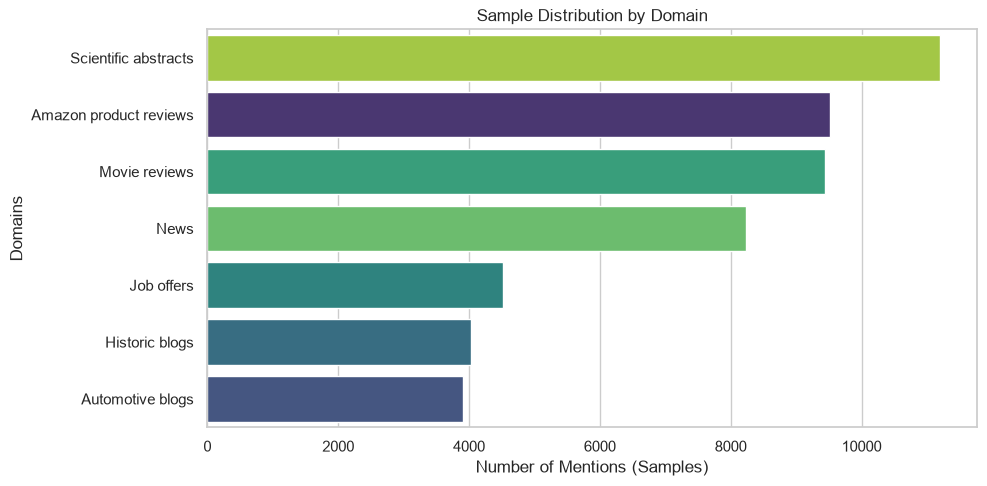

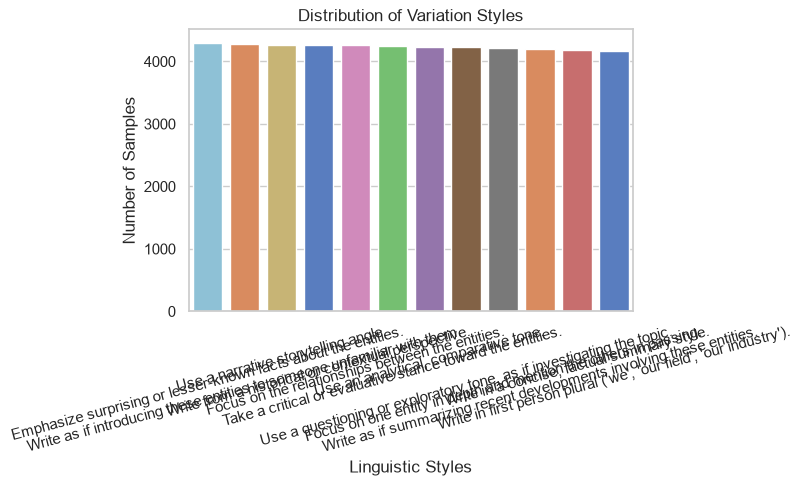

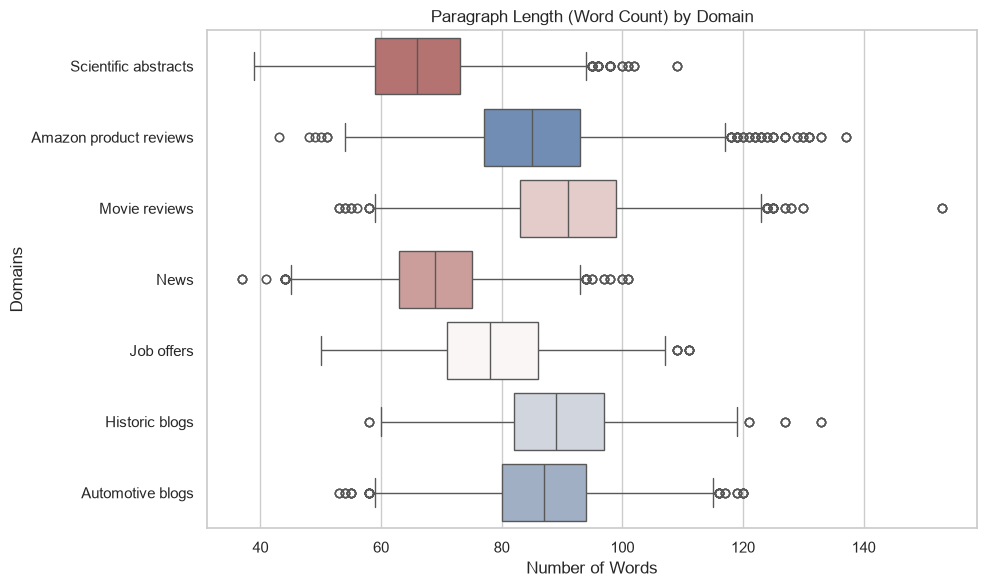

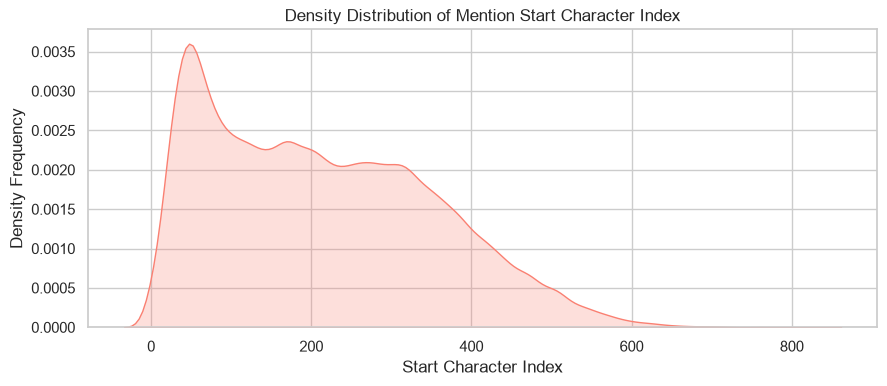

💾 All plots have been saved in High Definition in: 'generated data\plots/'


In [2]:
import glob
import json
import os
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Aesthetic configuration for professional reports
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 11

dossier_data = "generated data"
dossier_plots = os.path.join(dossier_data, "plots")
os.makedirs(dossier_plots, exist_ok=True)

# 1. Load all _CLEAN.jsonl files into a single Pandas DataFrame
fichiers_clean = glob.glob(os.path.join(dossier_data, "dataset_*_CLEAN.jsonl"))

all_data = []

for fichier in fichiers_clean:
    # Extract the domain name from the file name
    nom_fichier = os.path.basename(fichier)
    domaine = nom_fichier.replace("dataset_", "").replace("_CLEAN.jsonl", "").replace("_", " ")
    
    with open(fichier, "r", encoding="utf-8") as f:
        for line in f:
            if line.strip():
                item = json.loads(line)
                item["domain"] = domaine  # Add domain column
                # Calculate paragraph length in words
                item["paragraph_word_count"] = len(item.get("paragraph", "").split())
                all_data.append(item)

df = pd.DataFrame(all_data)

if df.empty:
    print("❌ No data found in _CLEAN.jsonl files. Please check your path or file names.")
else:
    print(f"📊 Data successfully loaded! Found {len(df)} samples across {df['domain'].nunique()} domains.\n")

    # ==========================================
    # GLOBAL DESCRIPTIVE STATISTICS (CONSOLE)
    # ==========================================
    print("📈 --- DESCRIPTIVE STATISTICS ---")
    print(f"• Total number of samples (1 paragraph = 1 mention): {len(df)}")
    print(f"• Unique target entities (Entity IDs): {df['entity_id'].nunique()}")
    print(f"• Average paragraph length: {df['paragraph_word_count'].mean():.1f} words")
    print(f"• Median paragraph length: {df['paragraph_word_count'].median():.1f} words\n")

    # ==========================================
    # PLOT 1: Sample Distribution by Domain
    # ==========================================
    plt.figure(figsize=(10, 5))
    order_domain = df["domain"].value_counts().index
    ax1 = sns.countplot(data=df, y="domain", order=order_domain, palette="viridis", hue="domain", legend=False)
    plt.title("Sample Distribution by Domain")
    plt.xlabel("Number of Mentions (Samples)")
    plt.ylabel("Domains")
    plt.tight_layout()
    plt.savefig(os.path.join(dossier_plots, "01_domain_distribution.png"), dpi=300)
    plt.show()

    # ==========================================
    # PLOT 2: Linguistic Style Distribution
    # ==========================================
    if "variation_style" in df.columns and df["variation_style"].notna().any():
        plt.figure(figsize=(8, 5))
        order_style = df["variation_style"].value_counts().index
        ax2 = sns.countplot(data=df, x="variation_style", order=order_style, palette="muted", hue="variation_style", legend=False)
        plt.title("Distribution of Variation Styles")
        plt.xlabel("Linguistic Styles")
        plt.ylabel("Number of Samples")
        plt.xticks(rotation=15)
        plt.tight_layout()
        plt.savefig(os.path.join(dossier_plots, "02_styles_distribution.png"), dpi=300)
        plt.show()

    # ==========================================
    # PLOT 3: Paragraph Length by Domain (Boxplot)
    # ==========================================
    plt.figure(figsize=(10, 6))
    sns.boxplot(data=df, x="paragraph_word_count", y="domain", order=order_domain, palette="vlag", hue="domain", legend=False)
    plt.title("Paragraph Length (Word Count) by Domain")
    plt.xlabel("Number of Words")
    plt.ylabel("Domains")
    plt.tight_layout()
    plt.savefig(os.path.join(dossier_plots, "03_paragraph_length_boxplot.png"), dpi=300)
    plt.show()

    # ==========================================
    # PLOT 4: Mention Position Density (Spans)
    # ==========================================
    plt.figure(figsize=(9, 4))
    sns.kdeplot(data=df, x="start", fill=True, color="salmon", bw_adjust=0.7)
    plt.title("Density Distribution of Mention Start Character Index")
    plt.xlabel("Start Character Index")
    plt.ylabel("Density Frequency")
    plt.tight_layout()
    plt.savefig(os.path.join(dossier_plots, "04_mention_position_density.png"), dpi=300)
    plt.show()

    print(f"💾 All plots have been saved in High Definition in: '{dossier_plots}/'")